# Lokalna wersja liczenia wskaźników

In [9]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Funkcje do wykrywania kompresji JPEG

def detect_jpeg_blockiness(image):
    """Wykrywa blokowość charakterystyczną dla JPEG (bloki 8x8 pikseli)
    
    Zwraca tablicę 8 współczynników blokowości, po jednym dla każdej granicy w bloku 8x8:
    - blockiness_ratios[0]: granica między pikselami 0-1
    - blockiness_ratios[1]: granica między pikselami 1-2
    - ...
    - blockiness_ratios[7]: granica między pikselami 7-8 (główna granica bloków)
    """
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) > 2 else image
    
    # Obliczanie różnic pomiędzy sąsiednimi pikselami (raz, zamiast wielokrotnie)
    h_diff = np.abs(np.diff(gray, axis=1))  # prawy sąsiad
    v_diff = np.abs(np.diff(gray, axis=0))  # dolny sąsiad
    
    blockiness_ratios = np.zeros(8, dtype=np.float32)
    
    # Dla każdej pozycji w bloku 8x8 (0-7)
    for offset in range(8):
        # Analizujemy wartości różnic na granicach dla danego offsetu
        h_block_diff = h_diff[:, offset::8]  # co 8 pikseli w poziomie, zaczynając od offset
        v_block_diff = v_diff[offset::8, :]  # co 8 pikseli w pionie, zaczynając od offset
        
        # Tworzymy maski zamiast używać kosztownego np.delete
        h_mask = np.ones(h_diff.shape[1], dtype=bool)
        h_mask[offset::8] = False
        v_mask = np.ones(v_diff.shape[0], dtype=bool)
        v_mask[offset::8] = False
        
        # Średnia różnica na granicach bloków vs pozostałe różnice
        block_diff_mean = (h_block_diff.mean() + v_block_diff.mean()) * 0.5
        non_block_diff_mean = (h_diff[:, h_mask].mean() + v_diff[v_mask, :].mean()) * 0.5
        
        # Współczynnik blokowości dla danej granicy
        blockiness_ratios[offset] = block_diff_mean / non_block_diff_mean if non_block_diff_mean > 0 else 0.0
    
    return blockiness_ratios


def estimate_jpeg_quality(image):
    """Szacuje jakość kompresji JPEG poprzez porównanie z rekompresją obrazu
    
    Funkcja ta próbuje określić jakość kompresji JPEG oryginalnego obrazu poprzez:
    1. Rekompresję obrazu z różnymi poziomami jakości (10%, 20%, ..., 100%)
    2. Porównanie każdej rekompresji z oryginałem przy użyciu MSE (Mean Squared Error)
    3. Wybranie poziomu jakości, który daje najbardziej podobny obraz
    
    UWAGA: Ta metoda może być niemiarodajna, ponieważ:
    - Nie uwzględnia pierwotnych parametrów kompresji JPEG
    - Nie różnicuje między obrazami nieskompresowanymi a wysoką jakością JPEG
    - Może dawać błędne wyniki dla obrazów z podwójną kompresją
    """
    # Konwersja do skali szarości jeśli obraz jest kolorowy
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) > 2 else image
    gray_float = gray.astype(np.float32)  # Konwersja raz zamiast wielokrotnie
    
    qualities = [10, 20, 30, 40, 50, 60, 70, 75, 78, 80, 82, 84, 86, 88, 89, 90, 91, 92, 93, 94, 95]
    best_quality = 100
    best_mse = float('inf')
    best_psnr = 0.0
    
    for quality in qualities:
        # Zapisz obraz do bufora z określoną jakością JPEG
        encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
        _, encoded_img = cv2.imencode('.jpg', gray, encode_param)
        
        # Odczytaj skompresowany obraz z powrotem
        decoded_img = cv2.imdecode(encoded_img, cv2.IMREAD_GRAYSCALE)
        
        # Oblicz MSE (Mean Squared Error) - średni błąd kwadratowy
        # Im mniejszy MSE, tym bardziej podobne obrazy
        mse = np.mean((gray_float - decoded_img.astype(np.float32)) ** 2)
        
        # Zapisz najlepszy wynik (najniższe MSE)
        if mse < best_mse:
            best_mse = mse
            best_quality = quality
            # Oblicz PSNR (Peak Signal-to-Noise Ratio) - stosunek sygnału do szumu
            # Im wyższy PSNR (w dB), tym lepsza jakość
            best_psnr = 10 * np.log10(65025.0 / mse) if mse > 0 else float('inf')
    
    return best_quality, best_psnr

def analyze_dct_spectrum(image):
    """Analizuje widmo częstotliwości poprzez DCT (Discrete Cosine Transform) na blokach 8x8"""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) > 2 else image
    
    # Przekształcamy obraz do wymiaru podzielnego przez 8
    h, w = gray.shape
    h_pad = h - (h % 8)
    w_pad = w - (w % 8)
    
    if h_pad == 0 or w_pad == 0:
        return 0.0, 0.0
    
    gray_crop = gray[:h_pad, :w_pad].astype(np.float32)
    
    # Obliczamy liczbę bloków
    num_blocks_h = h_pad // 8
    num_blocks_w = w_pad // 8
    num_blocks = num_blocks_h * num_blocks_w
    
    # Prealokacja tablicy na energie
    dct_energy = np.zeros(num_blocks, dtype=np.float32)
    
    # Obliczamy DCT dla każdego bloku (optymalizacja poprzez reshape)
    idx = 0
    for i in range(0, h_pad, 8):
        for j in range(0, w_pad, 8):
            block = gray_crop[i:i+8, j:j+8]
            dct = cv2.dct(block)
            # Energia składowych AC (wszystkie oprócz DC, czyli [0,0])
            dct_energy[idx] = np.sum(np.abs(dct)) - np.abs(dct[0, 0])
            idx += 1
    
    # Rozkład energii w blokach może wskazywać na kompresję JPEG
    return float(dct_energy.mean()), float(dct_energy.std())

# Główna funkcja do wykrywania kompresji JPEG
def detect_jpeg_compression(image_path):
    # Wczytaj obraz
    img = cv2.imread(image_path)
    if img is None:
        return "Nie można wczytać obrazu"
    
    # 1. Blokowość
    blockiness_ratios = detect_jpeg_blockiness(img)
    
    # 2. Analiza widma częstotliwości
    energy_mean, energy_std = analyze_dct_spectrum(img)
    
    # 3. Oszacowanie jakości kompresji (używamy połączonej metody)
    estimated_quality, psnr = estimate_jpeg_quality(img)
    
    # Statystyki blokowości
    blockiness_mean = float(np.mean(blockiness_ratios))
    blockiness_max = float(np.max(blockiness_ratios))
    blockiness_std = float(np.std(blockiness_ratios))
    
    # Budowanie słownika wyników
    result = {
        "energy_mean": energy_mean,
        "energy_std": energy_std,
        "estimated_quality": int(estimated_quality),
        "psnr": float(psnr) if np.isfinite(psnr) else None,
        "blockiness_mean": blockiness_mean,
        "blockiness_max": blockiness_max,
        "blockiness_std": blockiness_std
    }
    
    # Dodanie współczynników blokowości
    for i, val in enumerate(blockiness_ratios):
        result[f"blockiness_{i}"] = float(val)

    return result

# Generowanie grafik z różnymi kompresjami

In [17]:
from PIL import Image
import os

# Kompresuj obrazy z katalogu multiple-compression do JPG z różnymi jakościami kompresji
multiple_compression_dir = "multiple-compression-same-quality"

# Usuń wszystkie pliki inne niż png i ppm
for f in os.listdir(multiple_compression_dir):
    file_path = os.path.join(multiple_compression_dir, f)
    if os.path.isfile(file_path):
        ext = os.path.splitext(f)[1].lower()
        if ext not in ['.png', '.ppm']:
            try:
                os.remove(file_path)
                print(f"Usunięto {f}")
            except Exception as e:
                print(f"Błąd usuwania {f}: {e}")

# Pobierz wszystkie pliki PNG w katalogu
png_files = [f for f in os.listdir(multiple_compression_dir) if f.lower().endswith('.png')]

# Różne poziomy jakości kompresji JPEG
# quality_levels = [10, 30, 50, 70, 85, 95, "keep"]
quality_levels = [10, 30, 50, 65, 75, 85, 95]
# quality_levels = [70]

for png_file in png_files:
    png_path = os.path.join(multiple_compression_dir, png_file)
    base_name = os.path.splitext(png_file)[0]
    
    try:
        # Otwórz obraz PNG
        img = Image.open(png_path)
        
        # Zapisz z różnymi jakościami kompresji
        for quality in quality_levels:
            jpg_filename = f"{base_name}_q{quality}.jpg"
            jpg_path = os.path.join(multiple_compression_dir, jpg_filename)
            img.save(jpg_path, "JPEG", quality=quality)
            img.save
            print(f"Zapisano {jpg_filename}")
            
    except Exception as e:
        print(f"Błąd konwersji {png_file}: {e}")

# Wszystkie obrazy w katalogu multiple-compression które są w formacie *.jpg skompresuj kolejny raz do jpeg (standardowo). Oznaczaj je *.jpg.q_.jpg

# Pobierz wszystkie pliki JPG w katalogu
jpg_files = [f for f in os.listdir(multiple_compression_dir) if f.lower().endswith('.jpg')]

for jpg_file in jpg_files:
    jpg_path = os.path.join(multiple_compression_dir, jpg_file)
    
    try:
        # Otwórz obraz JPG
        img = Image.open(jpg_path)
        
        # Zapisz z różnymi jakościami kompresji z nową nazwą
        for quality in quality_levels:
            output_filename = f"{jpg_file}.q{quality}.jpg"
            output_path = os.path.join(multiple_compression_dir, output_filename)
            img.save(output_path, "JPEG", quality=quality)
            print(f"Zapisano {output_filename}")

            sub_image = Image.open(output_path)
            
            for sub_quality in quality_levels:
                sub_output_filename = f"{jpg_file}.q{quality}.q{sub_quality}.jpg"
                sub_output_path = os.path.join(multiple_compression_dir, sub_output_filename)
                sub_image.save(sub_output_path, "JPEG", quality=sub_quality)
                print(f"Zapisano {sub_output_filename}")

    except Exception as e:
        print(f"Błąd kompresji {jpg_file}: {e}")

Usunięto 01 (1)_q70.jpg
Usunięto 01 (1)_q70.jpg.q70.jpg
Usunięto 01 (1)_q70.jpg.q70.q70.jpg
Usunięto 01 (2)_q70.jpg
Usunięto 01 (2)_q70.jpg.q70.jpg
Usunięto 01 (2)_q70.jpg.q70.q70.jpg
Usunięto 01 (3)_q70.jpg
Usunięto 01 (3)_q70.jpg.q70.jpg
Usunięto 01 (3)_q70.jpg.q70.q70.jpg
Usunięto 01 (4)_q70.jpg
Usunięto 01 (4)_q70.jpg.q70.jpg
Usunięto 01 (4)_q70.jpg.q70.q70.jpg
Usunięto 01 (5)_q70.jpg
Usunięto 01 (5)_q70.jpg.q70.jpg
Usunięto 01 (5)_q70.jpg.q70.q70.jpg
Usunięto 01 (6)_q70.jpg
Usunięto 01 (6)_q70.jpg.q70.jpg
Usunięto 01 (6)_q70.jpg.q70.q70.jpg
Zapisano 01 (1)_q10.jpg
Zapisano 01 (1)_q30.jpg
Zapisano 01 (1)_q50.jpg
Zapisano 01 (1)_q65.jpg
Zapisano 01 (1)_q75.jpg
Zapisano 01 (1)_q85.jpg
Zapisano 01 (1)_q95.jpg
Zapisano 01 (2)_q10.jpg
Zapisano 01 (2)_q30.jpg
Zapisano 01 (2)_q50.jpg
Zapisano 01 (2)_q65.jpg
Zapisano 01 (2)_q75.jpg
Zapisano 01 (2)_q85.jpg
Zapisano 01 (2)_q95.jpg
Zapisano 01 (3)_q10.jpg
Zapisano 01 (3)_q30.jpg
Zapisano 01 (3)_q50.jpg
Zapisano 01 (3)_q65.jpg
Zapisano 01 (3)_

# Licznie wsk.

In [11]:
import os
import pandas as pd

# Get all files in the multiple-compression directory
image_files = [os.path.join(multiple_compression_dir, f) for f in os.listdir(multiple_compression_dir) 
               if os.path.isfile(os.path.join(multiple_compression_dir, f)) 
               and f.lower().endswith(('.jpg', '.jpeg', '.png', '.ppm'))]

# Initialize lists to store metrics
results = []

# Process each image file
for image_path in image_files:
    print(f"\nAnalyzing: {os.path.basename(image_path)}")
    try:
        img = cv2.imread(image_path)
        if img is None:
            print(f"  ❌ Could not load image")
            continue
        
        # Calculate blockiness metrics
        blockiness_ratios = detect_jpeg_blockiness(img)  # Tablica 8 wartości
        blockiness_ratio_max = np.max(blockiness_ratios)
        blockiness_ratio_mean = np.mean(blockiness_ratios)
        blockiness_ratio_std = np.std(blockiness_ratios)
        
        # Calculate DCT energy metrics
        energy_mean, energy_std = analyze_dct_spectrum(img)
        
        # Estimate JPEG quality
        estimated_quality, psnr_value = estimate_jpeg_quality(img)
        
        # Store results
        result_dict = {
            'filename': os.path.basename(image_path),
            'blockiness_ratio_max': blockiness_ratio_max,
            'blockiness_ratio_mean': blockiness_ratio_mean,
            'blockiness_ratio_std': blockiness_ratio_std,
            'energy_mean': energy_mean,
            'energy_std': energy_std,
            'estimated_quality': estimated_quality,
            'psnr': psnr_value
        }
        
        # Dodaj każdy współczynnik blokowości osobno
        for i, ratio in enumerate(blockiness_ratios):
            result_dict[f'blockiness_ratio_{i}'] = ratio
        
        results.append(result_dict)
        
        print(f"  ✓ Blockiness: max={blockiness_ratio_max:.3f}, mean={blockiness_ratio_mean:.3f}")
        print(f"  ✓ Energy: mean={energy_mean:.1f}, std={energy_std:.1f}")
        print(f"  ✓ Estimated quality: {estimated_quality}%, PSNR: {psnr_value:.2f} dB")
        
    except Exception as e:
        print(f"  ❌ Error processing: {e}")

print(f"\n{'='*60}")
print(f"✓ Processed {len(results)} images successfully")
print(f"{'='*60}")

# Convert to DataFrame for better analysis
df = pd.DataFrame(results)


Analyzing: 01 (1).png
  ✓ Blockiness: max=1.006, mean=1.000
  ✓ Energy: mean=201.2, std=268.8
  ✓ Estimated quality: 95%, PSNR: 45.13 dB

Analyzing: 01 (1).ppm
  ✓ Blockiness: max=1.006, mean=1.000
  ✓ Energy: mean=201.2, std=268.8
  ✓ Estimated quality: 95%, PSNR: 45.13 dB

Analyzing: 01 (1).ppm
  ✓ Blockiness: max=1.006, mean=1.000
  ✓ Energy: mean=201.2, std=268.8
  ✓ Estimated quality: 95%, PSNR: 45.13 dB

Analyzing: 01 (1)_q70.jpg
  ✓ Blockiness: max=1.006, mean=1.000
  ✓ Energy: mean=201.2, std=268.8
  ✓ Estimated quality: 95%, PSNR: 45.13 dB

Analyzing: 01 (1)_q70.jpg
  ✓ Blockiness: max=1.611, mean=1.007
  ✓ Energy: mean=115.1, std=252.7
  ✓ Estimated quality: 70%, PSNR: 74.20 dB

Analyzing: 01 (1)_q70.jpg.q70.jpg
  ✓ Blockiness: max=1.611, mean=1.007
  ✓ Energy: mean=115.1, std=252.7
  ✓ Estimated quality: 70%, PSNR: 74.20 dB

Analyzing: 01 (1)_q70.jpg.q70.jpg
  ✓ Blockiness: max=1.611, mean=1.007
  ✓ Energy: mean=115.1, std=252.6
  ✓ Estimated quality: 70%, PSNR: 75.12 dB

A

# Analiza i prezentacja wyników

In [12]:
# Podstawowe statystyki
print("=" * 80)
print("PODSUMOWANIE STATYSTYK DLA WSZYSTKICH OBRAZÓW")
print("=" * 80)
print(f"\nLiczba przeanalizowanych obrazów: {len(df)}")
print("\n" + "-" * 80)
print("WSKAŹNIKI BLOKOWOŚCI (Blockiness Ratios)")
print("-" * 80)
print(df[['blockiness_ratio_max', 'blockiness_ratio_mean', 'blockiness_ratio_std']].describe())

print("\n" + "-" * 80)
print("ENERGIA DCT (DCT Energy)")
print("-" * 80)
print(df[['energy_mean', 'energy_std']].describe())

print("\n" + "-" * 80)
print("JAKOŚĆ I PSNR")
print("-" * 80)
print(df[['estimated_quality', 'psnr']].describe())

# Dodatkowe analizy
print("\n" + "=" * 80)
print("ROZKŁAD SZACOWANEJ JAKOŚCI")
print("=" * 80)
quality_counts = df['estimated_quality'].value_counts().sort_index()
for quality, count in quality_counts.items():
    print(f"Jakość {quality:3d}%: {count:3d} obrazów {'█' * int(count / len(df) * 50)}")

# Identyfikacja obrazów z wysoką i niską blokowością
print("\n" + "=" * 80)
print("TOP 5 OBRAZÓW Z NAJWYŻSZĄ BLOKOWOŚCIĄ")
print("=" * 80)
top_blockiness = df.nlargest(5, 'blockiness_ratio_max')[['filename', 'blockiness_ratio_max', 'estimated_quality', 'psnr']]
print(top_blockiness.to_string(index=False))

print("\n" + "=" * 80)
print("TOP 5 OBRAZÓW Z NAJNIŻSZĄ BLOKOWOŚCIĄ")
print("=" * 80)
low_blockiness = df.nsmallest(5, 'blockiness_ratio_max')[['filename', 'blockiness_ratio_max', 'estimated_quality', 'psnr']]
print(low_blockiness.to_string(index=False))

PODSUMOWANIE STATYSTYK DLA WSZYSTKICH OBRAZÓW

Liczba przeanalizowanych obrazów: 30

--------------------------------------------------------------------------------
WSKAŹNIKI BLOKOWOŚCI (Blockiness Ratios)
--------------------------------------------------------------------------------
       blockiness_ratio_max  blockiness_ratio_mean  blockiness_ratio_std
count             30.000000              30.000000             30.000000
mean               1.374715               1.004632              0.145489
std                0.319573               0.004426              0.122171
min                1.006061               0.999996              0.004542
25%                1.008221               1.000014              0.005563
50%                1.491397               1.004939              0.189726
75%                1.610942               1.007281              0.235402
max                1.825152               1.012649              0.317793

------------------------------------------------------

## Wizualizacje

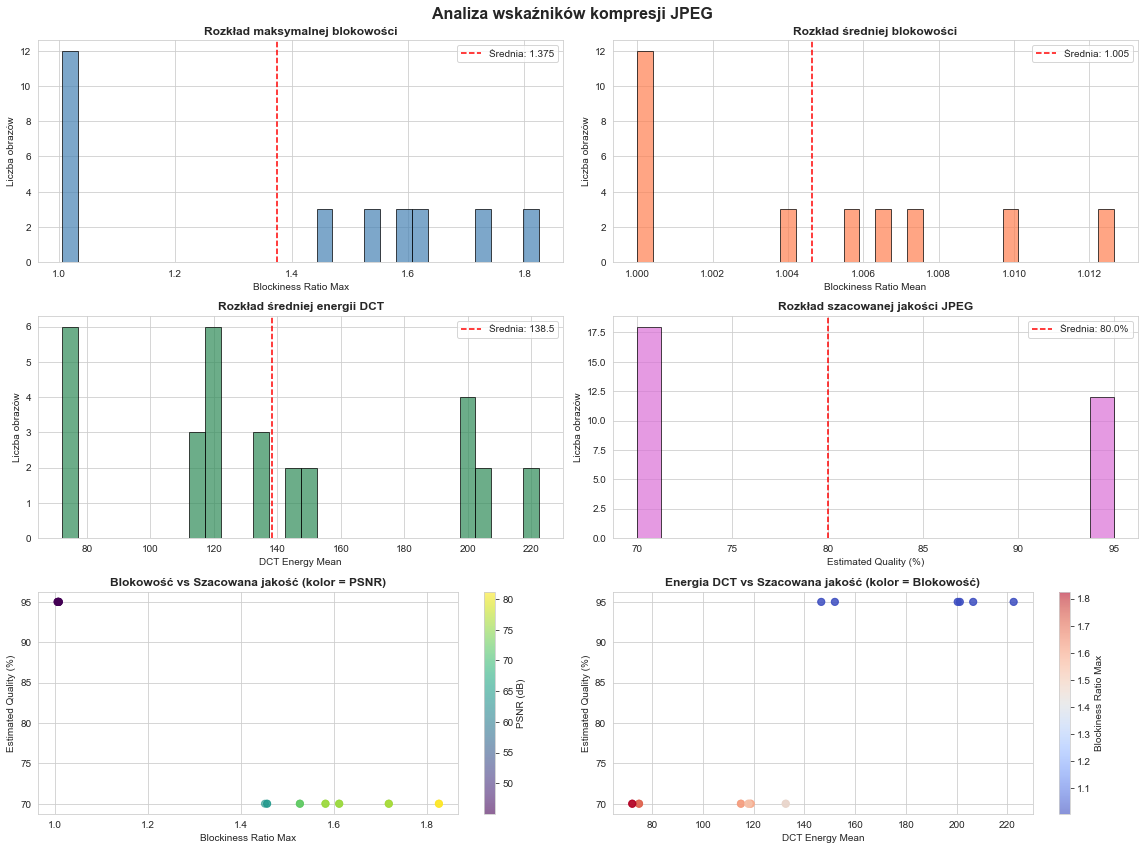

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ustawienia stylu
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (16, 12)

# Utworzenie siatki wykresów
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle('Analiza wskaźników kompresji JPEG', fontsize=16, fontweight='bold')

# 1. Histogram blokowości (max)
axes[0, 0].hist(df['blockiness_ratio_max'], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Rozkład maksymalnej blokowości', fontweight='bold')
axes[0, 0].set_xlabel('Blockiness Ratio Max')
axes[0, 0].set_ylabel('Liczba obrazów')
axes[0, 0].axvline(df['blockiness_ratio_max'].mean(), color='red', linestyle='--', 
                   label=f'Średnia: {df["blockiness_ratio_max"].mean():.3f}')
axes[0, 0].legend()

# 2. Histogram średniej blokowości
axes[0, 1].hist(df['blockiness_ratio_mean'], bins=30, color='coral', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Rozkład średniej blokowości', fontweight='bold')
axes[0, 1].set_xlabel('Blockiness Ratio Mean')
axes[0, 1].set_ylabel('Liczba obrazów')
axes[0, 1].axvline(df['blockiness_ratio_mean'].mean(), color='red', linestyle='--', 
                   label=f'Średnia: {df["blockiness_ratio_mean"].mean():.3f}')
axes[0, 1].legend()

# 3. Histogram energii DCT
axes[1, 0].hist(df['energy_mean'], bins=30, color='seagreen', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Rozkład średniej energii DCT', fontweight='bold')
axes[1, 0].set_xlabel('DCT Energy Mean')
axes[1, 0].set_ylabel('Liczba obrazów')
axes[1, 0].axvline(df['energy_mean'].mean(), color='red', linestyle='--', 
                   label=f'Średnia: {df["energy_mean"].mean():.1f}')
axes[1, 0].legend()

# 4. Histogram szacowanej jakości
axes[1, 1].hist(df['estimated_quality'], bins=20, color='orchid', edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Rozkład szacowanej jakości JPEG', fontweight='bold')
axes[1, 1].set_xlabel('Estimated Quality (%)')
axes[1, 1].set_ylabel('Liczba obrazów')
axes[1, 1].axvline(df['estimated_quality'].mean(), color='red', linestyle='--', 
                   label=f'Średnia: {df["estimated_quality"].mean():.1f}%')
axes[1, 1].legend()

# 5. Scatter: Blokowość vs Jakość
scatter1 = axes[2, 0].scatter(df['blockiness_ratio_max'], df['estimated_quality'], 
                              c=df['psnr'], cmap='viridis', alpha=0.6, s=50)
axes[2, 0].set_title('Blokowość vs Szacowana jakość (kolor = PSNR)', fontweight='bold')
axes[2, 0].set_xlabel('Blockiness Ratio Max')
axes[2, 0].set_ylabel('Estimated Quality (%)')
plt.colorbar(scatter1, ax=axes[2, 0], label='PSNR (dB)')

# 6. Scatter: Energia DCT vs Jakość
scatter2 = axes[2, 1].scatter(df['energy_mean'], df['estimated_quality'], 
                              c=df['blockiness_ratio_max'], cmap='coolwarm', alpha=0.6, s=50)
axes[2, 1].set_title('Energia DCT vs Szacowana jakość (kolor = Blokowość)', fontweight='bold')
axes[2, 1].set_xlabel('DCT Energy Mean')
axes[2, 1].set_ylabel('Estimated Quality (%)')
plt.colorbar(scatter2, ax=axes[2, 1], label='Blockiness Ratio Max')

plt.tight_layout()
plt.show()

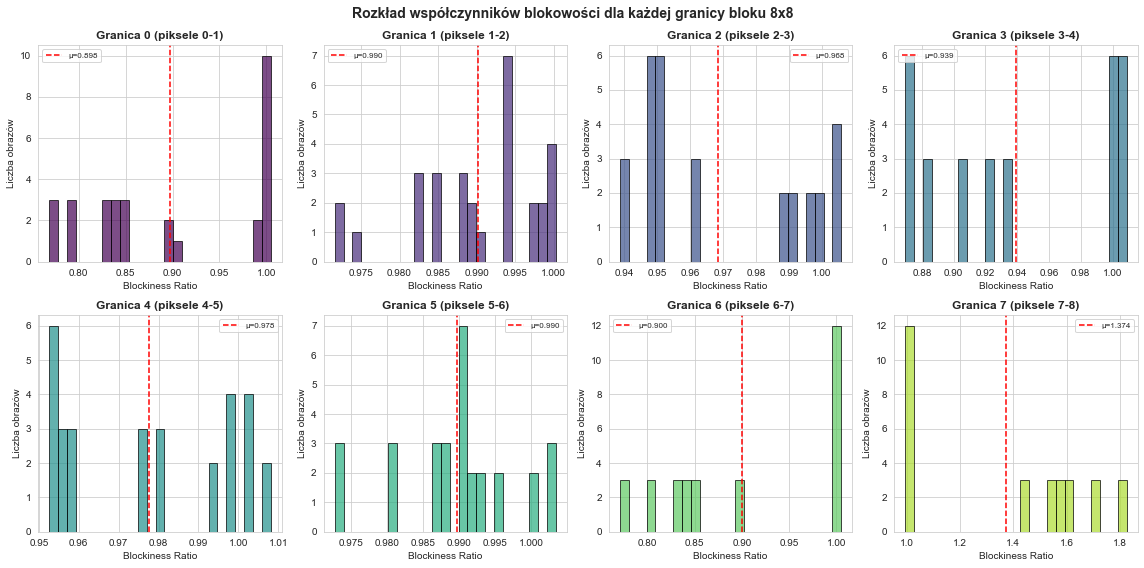


ŚREDNIE WARTOŚCI BLOKOWOŚCI DLA KAŻDEJ GRANICY
Granica 0 (piksele 0-1): średnia = 0.8975, odchylenie std = 0.0910
Granica 1 (piksele 1-2): średnia = 0.9902, odchylenie std = 0.0082
Granica 2 (piksele 2-3): średnia = 0.9685, odchylenie std = 0.0246
Granica 3 (piksele 3-4): średnia = 0.9394, odchylenie std = 0.0565
Granica 4 (piksele 4-5): średnia = 0.9776, odchylenie std = 0.0209
Granica 5 (piksele 5-6): średnia = 0.9897, odchylenie std = 0.0084
Granica 6 (piksele 6-7): średnia = 0.9004, odchylenie std = 0.0906
Granica 7 (piksele 7-8): średnia = 1.3738, odchylenie std = 0.3207

PORÓWNANIE GRANICY 7 (główna granica bloków) Z INNYMI
Średnia blokowość granicy 7: 1.3738
Średnia blokowość pozostałych granic: 0.9519
Różnica: 0.4219 (44.3%)


In [14]:
# Wizualizacja 8 współczynników blokowości
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Rozkład współczynników blokowości dla każdej granicy bloku 8x8', 
             fontsize=14, fontweight='bold')

for i in range(8):
    row = i // 4
    col = i % 4
    
    axes[row, col].hist(df[f'blockiness_ratio_{i}'], bins=25, 
                        color=plt.cm.viridis(i/8), edgecolor='black', alpha=0.7)
    axes[row, col].set_title(f'Granica {i} (piksele {i}-{i+1})', fontweight='bold')
    axes[row, col].set_xlabel('Blockiness Ratio')
    axes[row, col].set_ylabel('Liczba obrazów')
    
    mean_val = df[f'blockiness_ratio_{i}'].mean()
    axes[row, col].axvline(mean_val, color='red', linestyle='--', 
                          label=f'μ={mean_val:.3f}')
    axes[row, col].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Średnie wartości dla każdej granicy
print("\n" + "=" * 80)
print("ŚREDNIE WARTOŚCI BLOKOWOŚCI DLA KAŻDEJ GRANICY")
print("=" * 80)
for i in range(8):
    mean = df[f'blockiness_ratio_{i}'].mean()
    std = df[f'blockiness_ratio_{i}'].std()
    print(f"Granica {i} (piksele {i}-{i+1}): średnia = {mean:.4f}, odchylenie std = {std:.4f}")
    
# Sprawdzenie, czy granica 7 (główna granica bloków) ma najwyższą blokowość
print("\n" + "=" * 80)
print("PORÓWNANIE GRANICY 7 (główna granica bloków) Z INNYMI")
print("=" * 80)
boundary_7_mean = df['blockiness_ratio_7'].mean()
other_boundaries_mean = df[[f'blockiness_ratio_{i}' for i in range(7)]].mean().mean()
print(f"Średnia blokowość granicy 7: {boundary_7_mean:.4f}")
print(f"Średnia blokowość pozostałych granic: {other_boundaries_mean:.4f}")
print(f"Różnica: {boundary_7_mean - other_boundaries_mean:.4f} ({(boundary_7_mean / other_boundaries_mean - 1) * 100:.1f}%)")

## Macierz korelacji wskaźników

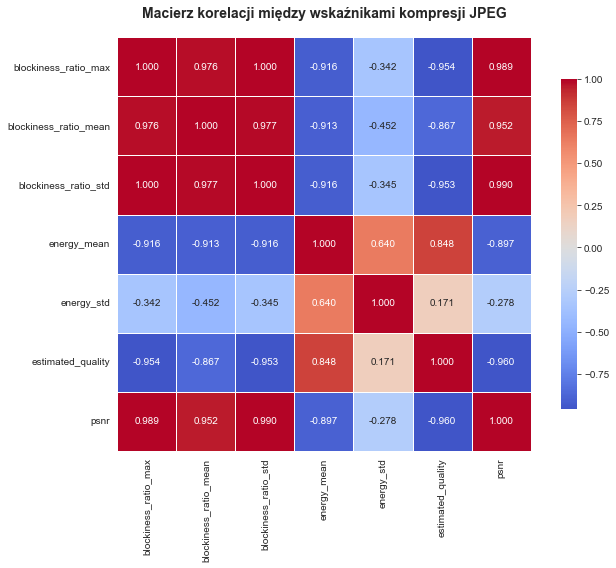


SILNE KORELACJE (|r| > 0.5)
blockiness_ratio_max           <-> blockiness_ratio_mean         : r = +0.976
blockiness_ratio_max           <-> blockiness_ratio_std          : r = +1.000
blockiness_ratio_max           <-> energy_mean                   : r = -0.916
blockiness_ratio_max           <-> estimated_quality             : r = -0.954
blockiness_ratio_max           <-> psnr                          : r = +0.989
blockiness_ratio_mean          <-> blockiness_ratio_std          : r = +0.977
blockiness_ratio_mean          <-> energy_mean                   : r = -0.913
blockiness_ratio_mean          <-> estimated_quality             : r = -0.867
blockiness_ratio_mean          <-> psnr                          : r = +0.952
blockiness_ratio_std           <-> energy_mean                   : r = -0.916
blockiness_ratio_std           <-> estimated_quality             : r = -0.953
blockiness_ratio_std           <-> psnr                          : r = +0.990
energy_mean                    <-> 

In [15]:
# Macierz korelacji
correlation_cols = ['blockiness_ratio_max', 'blockiness_ratio_mean', 'blockiness_ratio_std',
                   'energy_mean', 'energy_std', 'estimated_quality', 'psnr']

correlation_matrix = df[correlation_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.3f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Macierz korelacji między wskaźnikami kompresji JPEG', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Wyświetl silne korelacje
print("\n" + "=" * 80)
print("SILNE KORELACJE (|r| > 0.5)")
print("=" * 80)
for i in range(len(correlation_cols)):
    for j in range(i+1, len(correlation_cols)):
        corr_value = correlation_matrix.iloc[i, j]
        if abs(corr_value) > 0.5:
            print(f"{correlation_cols[i]:30s} <-> {correlation_cols[j]:30s}: r = {corr_value:+.3f}")

## Eksport wyników do CSV

In [16]:
# Zapisz wyniki do pliku CSV
output_file = 'multiple-compression-results/analysis_results.csv'

# Utwórz katalog jeśli nie istnieje
os.makedirs('multiple-compression-results', exist_ok=True)

# Zapisz pełne wyniki
df.to_csv(output_file, index=False, encoding='utf-8')
print(f"✓ Pełne wyniki zapisane do: {output_file}")

# Zapisz również uproszczoną wersję z podstawowymi wskaźnikami
simplified_cols = ['filename', 'blockiness_ratio_max', 'blockiness_ratio_mean', 
                  'energy_mean', 'energy_std', 'estimated_quality', 'psnr']
df[simplified_cols].to_csv('multiple-compression-results/analysis_results_simplified.csv', 
                           index=False, encoding='utf-8')
print(f"✓ Uproszczone wyniki zapisane do: multiple-compression-results/analysis_results_simplified.csv")

# Zapisz statystyki podsumowujące
with open('multiple-compression-results/summary_stats.txt', 'w', encoding='utf-8') as f:
    f.write("=" * 80 + "\n")
    f.write("PODSUMOWANIE STATYSTYK ANALIZY KOMPRESJI JPEG\n")
    f.write("=" * 80 + "\n\n")
    f.write(f"Liczba przeanalizowanych obrazów: {len(df)}\n")
    f.write(f"Katalog: {multiple_compression_dir}\n\n")
    
    f.write("-" * 80 + "\n")
    f.write("WSKAŹNIKI BLOKOWOŚCI\n")
    f.write("-" * 80 + "\n")
    f.write(df[['blockiness_ratio_max', 'blockiness_ratio_mean', 'blockiness_ratio_std']].describe().to_string())
    f.write("\n\n")
    
    f.write("-" * 80 + "\n")
    f.write("ENERGIA DCT\n")
    f.write("-" * 80 + "\n")
    f.write(df[['energy_mean', 'energy_std']].describe().to_string())
    f.write("\n\n")
    
    f.write("-" * 80 + "\n")
    f.write("JAKOŚĆ I PSNR\n")
    f.write("-" * 80 + "\n")
    f.write(df[['estimated_quality', 'psnr']].describe().to_string())
    f.write("\n")

print(f"✓ Statystyki podsumowujące zapisane do: multiple-compression-results/summary_stats.txt")

print("\n" + "=" * 80)
print("WSZYSTKIE WYNIKI ZOSTAŁY ZAPISANE")
print("=" * 80)

✓ Pełne wyniki zapisane do: multiple-compression-results/analysis_results.csv
✓ Uproszczone wyniki zapisane do: multiple-compression-results/analysis_results_simplified.csv
✓ Statystyki podsumowujące zapisane do: multiple-compression-results/summary_stats.txt

WSZYSTKIE WYNIKI ZOSTAŁY ZAPISANE
